<a href="https://colab.research.google.com/github/gjardim27/NewCurve/blob/claude%2Facoustic-streaming-piv-m3hdpa/Gui_Process_PIV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

replace 0 values in velocity arrays with nans

if that doesn't fix it, determine theta bounds

replace circle fit with curve_fit call

fix scale factor


In [ ]:
# @title Setup

# Install packages with pip
# %pip install pint
%pip install pyfluids
# %pip install scipy
%pip install lvpyio==1.3.1


# @title Import dependencies
import gspread
import google.colab, google.auth
from google.colab import drive
import matplotlib.pyplot as plt
import matplotlib.patches
import matplotlib.lines
import matplotlib
import numpy as np
import os
import pandas as pd
import lvpyio as lv
import pyfluids
import datetime
import time
import scipy
import yaml
import scipy.optimize
import scipy.interpolate

plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'


# Mount google drive (must be separate cell to avoid re-mounting errors)
# allows reading of text/.csv files from google drive, but NOT google sheets files.
force_remount = False # @param {type:"boolean"}
drive.mount('/content/drive', force_remount=force_remount)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 48.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 251.7/251.7 kB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 38.4 MB/s eta 0:00:00
Mounted at /content/drive


# PIV Perturbation Analysis

Scale is 0.019744 mm / box


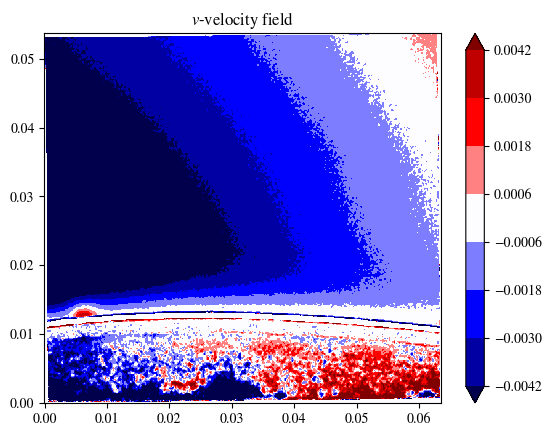

In [ ]:
# @title Load PIV

# Name of directory containing PIV data
piv_root = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/PIV/N65_WT_PIV_Flow_Fields"
mi_root = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/Model Installation/InstallationRunFolders"

# name of lavision project containing PIV data
project_run = 1387
project = f"CJK_NACA651412_RUN{project_run}"

project_path = os.path.join(piv_root, project)

# photo directory
photo_dir = os.path.join(mi_root, f"Run{project_run}")

c = 0.2

# Run number for processed PIV
run = 1414 # @param {type: "integer"}
#identify folder corresponding to run (regardless of TP number)
run_dir = next(f for f in os.listdir(project_path) if f.startswith(f"RUN{run}") and not f.endswith(".set"))

run_path = os.path.join(project_path, run_dir)

inst_piv_path = os.path.join(run_path, "PIV_MP(3x8x8_50%ov_ImgCorr)")
avgd_piv_path = os.path.join(inst_piv_path, "Avg_Stdev")
u_lim = 4.2e-3

piv_avg_b, piv_std_b = lv.read_set(avgd_piv_path)  # set has 2 buffers

scale = piv_avg_b[0].scales.x.slope
scale_unit = piv_avg_b[0].scales.x.unit
print(f"Scale is {scale} {scale_unit} / box")

piv_avg = piv_avg_b.as_masked_array()
mask = piv_avg.mask["u"][::-1,::-1]
u = piv_avg.data["u"][::-1,::-1]
v = piv_avg.data["v"][::-1,::-1]
# *scale converts to mm, *1000 to m, and /c to x/c
x = np.arange(u.shape[1])*scale/1000/c
y = np.arange(u.shape[0])*scale/1000/c
X, Y = np.meshgrid(x, y)

ticks = np.linspace(-u_lim, u_lim, 8, endpoint=True)
cmap = plt.colormaps['seismic']
norm = matplotlib.colors.BoundaryNorm(
    boundaries=ticks,
    ncolors=256,
    extend='both',
)

plt.pcolormesh(X, Y, v, cmap=cmap, norm=norm)
plt.colorbar(ticks=ticks)
plt.title('$v$-velocity field')

plt.show()


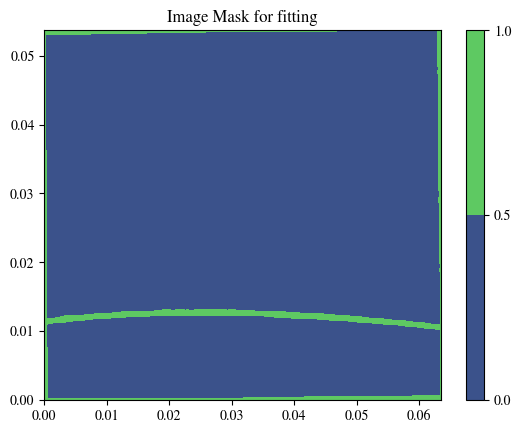

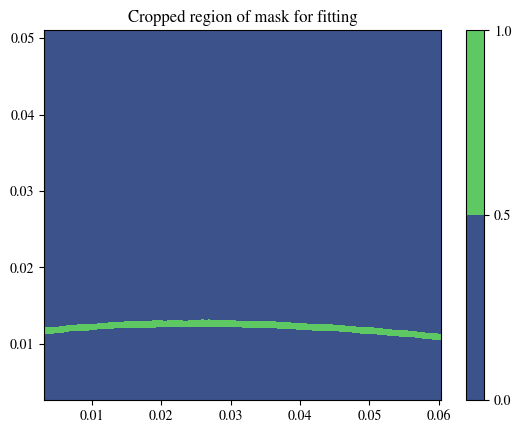

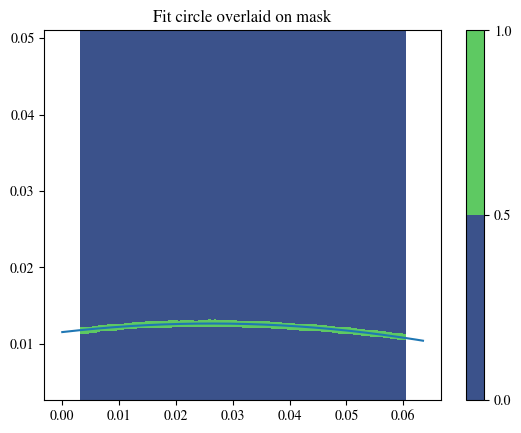

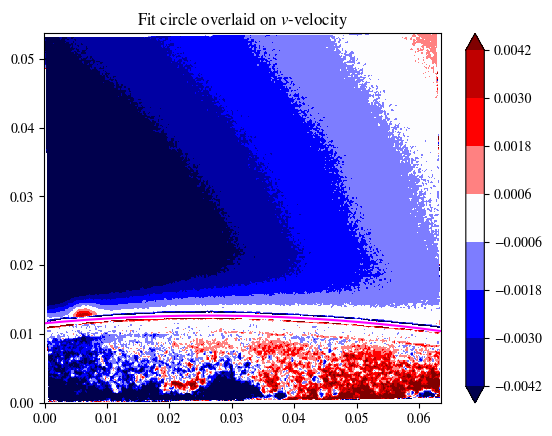

In [ ]:
# @title fit circle
plt.contourf(X, Y, mask)
plt.colorbar()
plt.title("Image Mask for fitting")
plt.show()

fit_region_prop = 0.9 # @param {type:"number"}
edge_prop = (1-fit_region_prop)/2
x_sz = len(x)
y_sz = len(y)
ix_min = int(edge_prop*x_sz)
iy_min = int(edge_prop*y_sz)
x_fit = x[ix_min:-ix_min]
y_fit = y[iy_min:-iy_min]
mask_fit = mask[iy_min:-iy_min,ix_min:-ix_min]
X_fit, Y_fit = np.meshgrid(x_fit, y_fit)

plt.contourf(X_fit, Y_fit, mask_fit)
plt.colorbar()
plt.title("Cropped region of mask for fitting")
plt.show()

def circle_to_fit(xc, yc, r, xp, yp, mask):
    """
    fit a circle to a set of points
    input arguments:
    xc: scalar x coordinate of center (to be fit)
    yc: scalar y coordinate of center (to be fit)
    r: scalar radius of circle (to be fit)
    xp: ndarray of x values of data points
    yp: ndarray of y values of data points
    """
    score = 0
    n, m = xp.shape
    for i in range(n):
        for j in range(m):
            x = xp[i,j]
            y = yp[i,j]
            if mask[i,j]:
                score += (np.sqrt((x-xc)**2 + (y-yc)**2) - r)**2
    score = np.sqrt(score)
    return score


minimization_function = lambda p: circle_to_fit(p[0], p[1], p[2], X_fit, Y_fit, mask_fit)
d_grid = np.sqrt((np.max(x)-np.min(x))**2 + (np.max(y)-np.min(y))**2)  # diameter (diagonal) of image
p0 = (0, 0, d_grid)
res = scipy.optimize.minimize(minimization_function, p0).x
xc, yc, r = res
circle = lambda x: yc + np.sqrt(r**2 - (x-xc)**2)

plt.plot(x, circle(x))
plt.contourf(X_fit, Y_fit, mask_fit)
plt.colorbar()
plt.title("Fit circle overlaid on mask")
plt.show()

plt.plot(x, circle(x), c='magenta')
plt.pcolormesh(X, Y, v, cmap=cmap, norm=norm)
plt.colorbar(ticks=ticks)
plt.title("Fit circle overlaid on $v$-velocity")
plt.show()




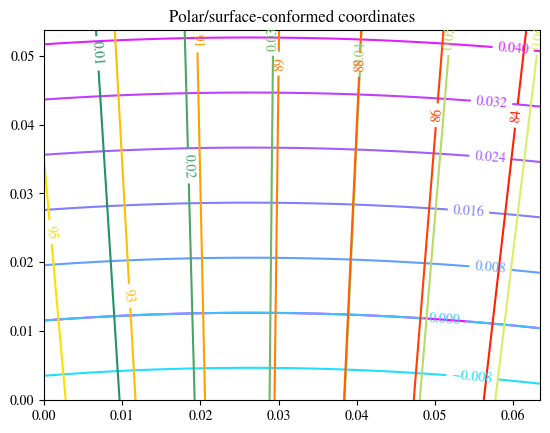

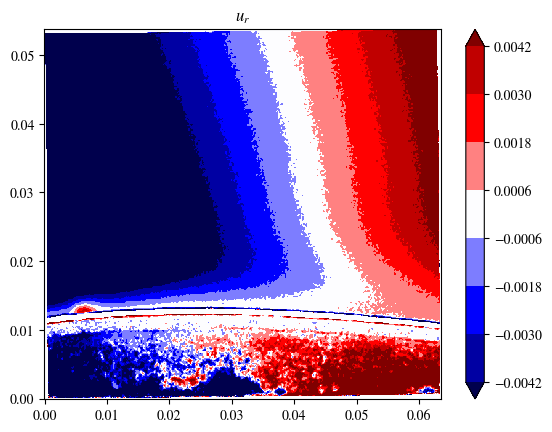

In [ ]:
# @title Convert to surface-conformed coordinates
X_shifted = X - xc
Y_shifted = Y - yc

rho = np.sqrt(X_shifted**2 + Y_shifted**2) - r
theta = np.arctan2(Y_shifted, X_shifted)

theta2xi = lambda phi:  r*(np.max(theta) - phi)
xi2theta = lambda xi: np.max(theta) - xi/r

xi = theta2xi(theta)

ur = (u*X_shifted+v*Y_shifted)/(rho+r)

plt.plot(x, circle(x), c='magenta')

rho_cs = plt.contour(X, Y, rho, cmap="cool")
plt.clabel(rho_cs, rho_cs.levels)

xi_cs = plt.contour(X, Y, xi, cmap="summer")
plt.clabel(xi_cs, xi_cs.levels)

theta_cs = plt.contour(X, Y, theta, cmap="autumn")
plt.clabel(theta_cs, theta_cs.levels, fmt=lambda phi: f"{np.rad2deg(phi):0.0f}")

plt.title("Polar/surface-conformed coordinates")
plt.show()

plt.title("$u_r$")
urc = plt.pcolormesh(X, Y, ur, cmap=cmap, norm=norm)
plt.colorbar(urc, ticks=ticks)
plt.show()



a: 3.93e-03, xbar: 6.37e-03, sigma: 1.17e-03
a: 2.27e-03, xbar: 6.41e-03, sigma: 1.55e-03
a: 1.50e-03, xbar: 6.45e-03, sigma: 1.84e-03
a: 9.39e-04, xbar: 6.50e-03, sigma: 2.18e-03
a: 4.49e-04, xbar: 7.32e-03, sigma: 1.97e-03


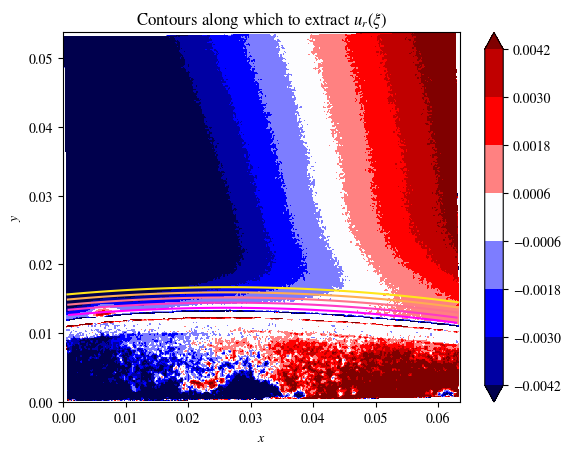

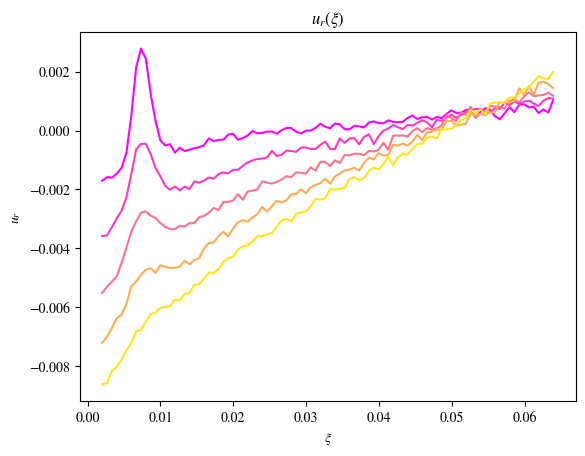

In [ ]:
# @title Plot $u_r(\xi)$ for various $\eta$

# define ur for interpolation
ur_cmap = matplotlib.colormaps['spring']
ur_interp = scipy.interpolate.RegularGridInterpolator((x, y), ur.T, fill_value=np.nan, bounds_error=False)

maxtheta = xi2theta(np.min(xi))
theta_arr = np.linspace(np.min(theta), maxtheta, 100)
# theta_arr = theta_arr[3:-4]
theta_deg_arr = np.rad2deg(theta_arr)
etavalues = np.linspace(10e-4, 40e-4, 5)

def color(eta):
    # put eta between 0 and 1
    eta_scaled = (eta-np.min(etavalues))/(np.max(etavalues)-np.min(etavalues))
    # remove last 10% which is too yellow
    eta_scaled = eta_scaled*0.9
    return ur_cmap(eta_scaled)

xwid_fig_ur_xi = 0.03

# fit Gaussian of amplitude a, mean mu, and std sigma summed with 2nd order polynomial
ur_curve = lambda x, a, mu, sigma, b, m, q, c: a*np.exp(-(x-mu)**2/(2*sigma**2)) + b + m*x + q*x**2 + c*x**3

plt.figure(2)
plt.title(r"$u_r(\xi)$")
plt.xlabel(r"$\xi$")
plt.ylabel("$u_r$")
# plt.xlim(0, xwid_fig_ur_xi)

plt.figure(1)
plt.pcolormesh(X, Y, ur, cmap=cmap, norm=norm)
plt.colorbar(ticks=ticks)
plt.title(r"Contours along which to extract $u_r(\xi)$")
y_0fig_ur_xi = 0.005
# plt.xlim(0, xwid_fig_ur_xi)
# plt.ylim(y_0fig_ur_xi, y_0fig_ur_xi+xwid_fig_ur_xi)
plt.xlabel("$x$")
plt.ylabel("$y$")
for eta in etavalues:
    r_eta = eta + r

    x_arr, y_arr = r_eta*np.cos(theta_arr)+xc, r_eta*np.sin(theta_arr)+yc
    xi_arr = theta2xi(theta_arr)
    ur_arr = ur_interp((x_arr, y_arr))

    # remove nans aand 0s from arrays
    good_indices = np.logical_and(np.logical_not(np.isnan(ur_arr)), ur_arr != 0)
    x_arr = x_arr[good_indices]
    y_arr = y_arr[good_indices]
    xi_arr = xi_arr[good_indices]
    ur_arr = ur_arr[good_indices]

    urpopt, urpcov = scipy.optimize.curve_fit(ur_curve, x_arr[1:-2], ur_arr[1:-2], (0.006, 0.007, 0.001, -0.004, 0.11, -0.5, 0))
    a_fit, mu_fit, sigma_fit, b_fit, m_fit, q_fit, c_fit = urpopt
    if mu_fit < np.min(x_arr):
        a_fit = 0
        sigma_fit = np.nan
        xbar = np.nan
    ur_curve_fit = lambda x: ur_curve(x, a_fit, mu_fit, sigma_fit, b_fit, m_fit, q_fit, c_fit)

    plt.figure(1)  # contours overlaid on ur
    plt.plot(x_arr, y_arr, "-", c=color(eta))

    plt.figure(2)  # ur(xi)
    plt.plot(xi_arr, ur_arr, "-", c=color(eta))
    # plt.plot(xi_arr, ur_curve_fit(x_arr), '--', c=color(eta))
    print(f'a: {a_fit:1.2e}, xbar: {mu_fit:1.2e}, sigma: {sigma_fit:1.2e}')


plt.show()


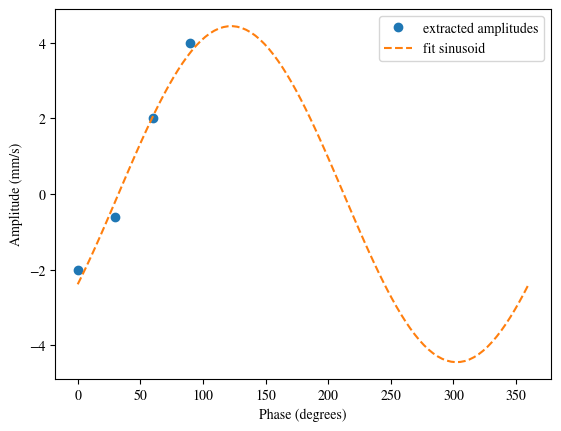

4.44e+00


In [ ]:
phase_scr = np.linspace(90, 0, 4)
amps_scr = np.array([4, 2, -0.6, -2])  # 240 Hz
# amps_scr = np.array([0.6, 0.9, 1, 1])  # 30  Hz


plotting_phases = np.linspace(0, 360, 100)

sin_fit_params = lambda x, a_sin, phi_sin: a_sin*np.sin(2*np.pi*x/360+phi_sin)

sin_popt = scipy.optimize.curve_fit(sin_fit_params, phase_scr, amps_scr)
a_sin_fit, phi_sin_fit = sin_popt[0]

sin_fit = lambda x: sin_fit_params(x, a_sin_fit, phi_sin_fit)

plt.plot(phase_scr, amps_scr, 'o', label="extracted amplitudes")
plt.plot(plotting_phases, sin_fit(plotting_phases), "--", label="fit sinusoid")
plt.xlabel("Phase (degrees)")
plt.ylabel("Amplitude (mm/s)")
plt.legend()
plt.show()

print(f"{a_sin_fit:1.2e}")

Files in run_path:
PIV_MP(3x16x16_50%ov_ImgCorr).set
PIV_MP(3x16x16_50%ov_ImgCorr)
RUN1178TP1.pkl
Scale: 0.0997142 mm/box


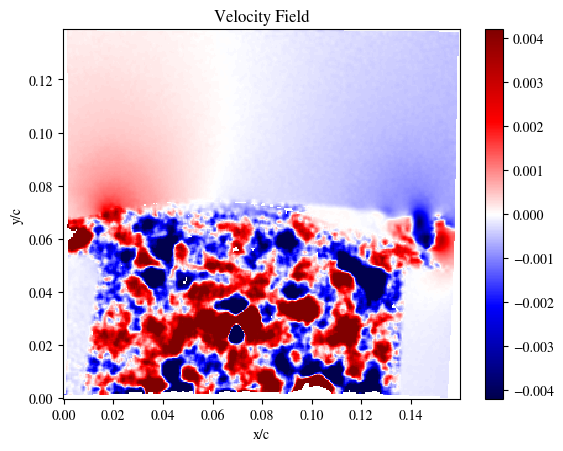

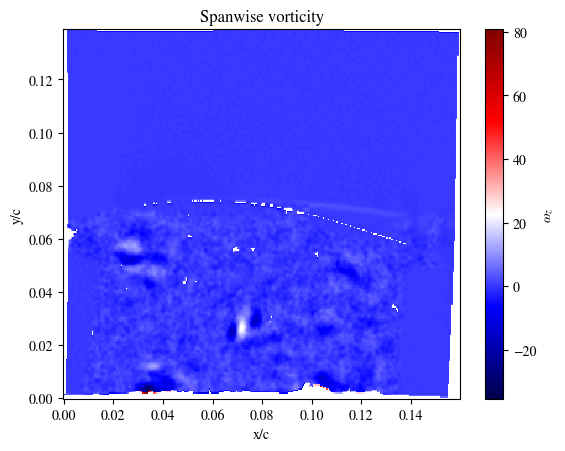

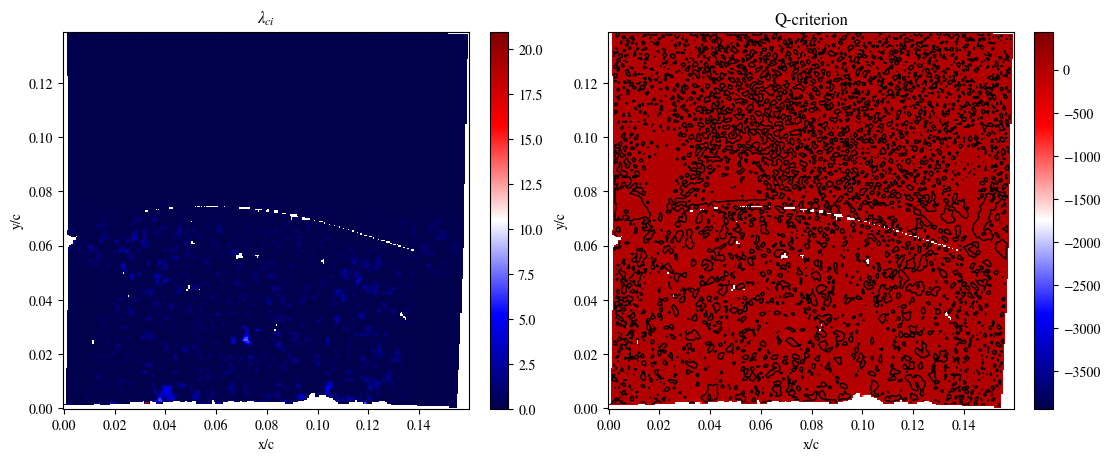

In [ ]:
# @title Vorticity Identification from Instanteneous PIV

# Name of directory containing PIV data
piv_root = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/PIV/N65_WT_PIV_Flow_Fields"
mi_root = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/Model Installation/InstallationRunFolders"

# Name of LaVision project containing PIV data
project_run = 1117
project = f"CJK_NACA651412_RUN{project_run}" # Folder name

project_path = os.path.join(piv_root, project)

# Photo directory
photo_dir = os.path.join(mi_root, f"Run{project_run}")

c = 0.2
# Run number
run = 1178 # @param {type: "integer"}
#identify folder corresponding to run (regardless of TP number)
run_dir = next(f for f in os.listdir(project_path) if f.startswith(f"RUN{run}") and not f.endswith(".set"))

run_path = os.path.join(project_path, run_dir)

# List files in the run_path to find the correct PIV folder name
print("Files in run_path:")
for f in os.listdir(run_path):
    print(f)

# Load Data
inst_piv_path = os.path.join(run_path, "PIV_MP(3x16x16_50%ov_ImgCorr)")
u_lim = 4.2e-3 # Velocity Limits

# Load the LaVision SET containing instantaneous PIV frames
buffer = lv.read_set(inst_piv_path)
frames = buffer[0]

# Create Mask and take scale and unit from LaVision Set
piv = frames[0].as_masked_array()
scale = frames[0].scales.x.slope
unit  = frames[0].scales.x.unit
print(f"Scale: {scale} {unit}/box")

# Extract U and V velocity components
mask = piv.mask["u"][::-1, ::-1]
U = piv.data["u"][::-1, ::-1]
V = piv.data["v"][::-1, ::-1]
U = U / 1000
V = V / 1000
U = U.astype(float)
V = V.astype(float)

U[mask] = np.nan
V[mask] = np.nan

# Build Grid
x = np.arange(U.shape[1])*scale/1000/c
y = np.arange(U.shape[0])*scale/1000/c
X, Y = np.meshgrid(x, y)

# quick plot to verify orientation/values
u_lim = 4.2e-3
plt.figure()
plt.pcolormesh(X, Y, V, cmap='seismic', vmin=-u_lim, vmax=u_lim, shading='nearest')
plt.colorbar(); plt.title('Velocity Field'); plt.xlabel('x/c'); plt.ylabel('y/c')
plt.show()

def safe_gradient(F, dx, dy, mask):
    "Compute gradient, treating masked points as 0 to avoid NaN propagation."
    F_filled = F.copy()
    F_filled[mask] = 0.0
    dF_dy, dF_dx = np.gradient(F_filled, dy, dx)
    dF_dx[mask] = np.nan
    dF_dy[mask] = np.nan
    return dF_dy, dF_dx

dU_dy, dU_dx = safe_gradient(U, dx, dy, mask)
dV_dy, dV_dx = safe_gradient(V, dx, dy, mask)

#Define Important Flow Equations
def gradients(U, V, X, Y, mask):
  dx = np.median(np.diff(X[0,:]))
  dy = np.median(np.diff(Y[:,0]))
  dU_dy, dU_dx = safe_gradient(U, dx, dy, mask)
  dV_dy, dV_dx = safe_gradient(V, dx, dy, mask)
  dU_dx[mask] = np.nan
  dU_dy[mask] = np.nan
  dV_dx[mask] = np.nan
  dV_dy[mask] = np.nan
  tr = dU_dx + dV_dy
  det = dU_dx * dV_dy - dU_dy * dV_dx
  disc = tr**2 - 4.0*det
  return dx, dy, dU_dy, dU_dx, dV_dy, dV_dx, tr, det, disc

dx, dy, dU_dy, dU_dx, dV_dy, dV_dx, tr, det, disc = gradients(U, V, X, Y, mask)


def swirling_strength(dU, dV, disc, mask):
  lamci = np.zeros_like(dU)
  m = disc < 0.0
  lamci = np.zeros_like(dU)
  lamci[m] = 0.5*np.sqrt(-disc[m])
  lamci[mask] = np.nan
  return lamci

lamci = swirling_strength(dU_dx, dV_dy, disc, mask)
# Q-Criterion
def q_criterion(dU_dx, dU_dy, dV_dx, dV_dy, mask):
    # Strain-rate tensor
    sxx = dU_dx
    syy = dV_dy
    sxy = 0.5 * (dU_dy + dV_dx)

    # Rotation (out-of-plane vorticity)
    omega_z = dV_dx - dU_dy

    S2 = sxx**2 + syy**2 + 2.0 * sxy**2
    Omega2 = 0.5 * omega_z**2

    Q = 0.5 * (Omega2 - S2)
    Q[mask] = np.nan
    return Q

Q = q_criterion(dU_dx, dU_dy, dV_dx, dV_dy, mask)
omega_z = dV_dx - dU_dy

plt.figure()
plt.pcolormesh(X, Y, omega_z, shading='nearest', cmap='seismic')
plt.colorbar(label=r'$\omega_z$')
plt.title('Spanwise vorticity')
plt.xlabel('x/c'); plt.ylabel('y/c')
plt.show()

fig, ax = plt.subplots(1,2, figsize=(11,4.5), constrained_layout=True)

im0 = ax[0].pcolormesh(X, Y, lamci, shading='nearest', cmap='seismic')
ax[0].set_title(r'$\lambda_{ci}$'); ax[0].set_xlabel('x/c'); ax[0].set_ylabel('y/c')
fig.colorbar(im0, ax=ax[0])

im1 = ax[1].pcolormesh(X, Y, Q, shading='nearest', cmap='seismic')
ax[1].contour(X, Y, Q, levels=[0.0], colors='k', linewidths=1.0)  # Q=0 boundary
ax[1].set_title('Q-criterion'); ax[1].set_xlabel('x/c'); ax[1].set_ylabel('y/c')
fig.colorbar(im1, ax=ax[1])

plt.show()




Files in run_path:
PIV_MP(3x16x16_50%ov_ImgCorr).set
PIV_MP(3x16x16_50%ov_ImgCorr)
RUN1178TP1.pkl

Loaded 1 instantaneous PIV frames
Scale: 0.0997142 mm/box


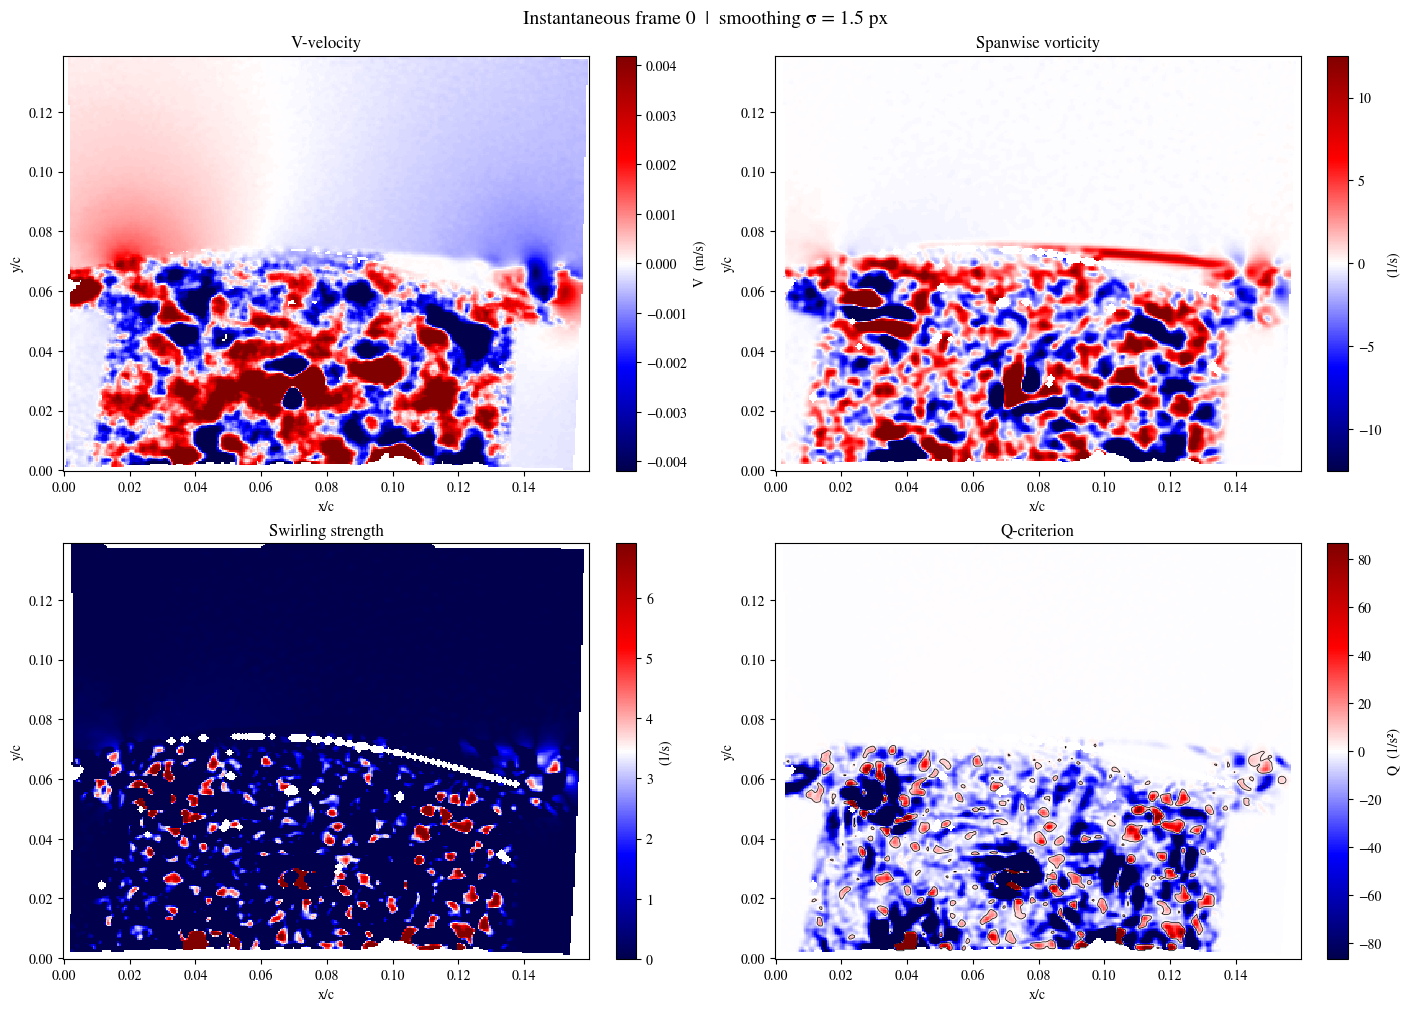

In [ ]:
# @title Vorticity Identification from Instantaneous PIV (Corrected)

import scipy.ndimage

# ── Data Loading ──
piv_root = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/PIV/N65_WT_PIV_Flow_Fields"
mi_root  = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/Model Installation/InstallationRunFolders"

project_run = 1117
project = f"CJK_NACA651412_RUN{project_run}"
project_path = os.path.join(piv_root, project)
photo_dir = os.path.join(mi_root, f"Run{project_run}")

c = 0.2  # chord length [m]
run = 1178  # @param {type: "integer"}
run_dir = next(f for f in os.listdir(project_path)
               if f.startswith(f"RUN{run}") and not f.endswith(".set"))
run_path = os.path.join(project_path, run_dir)

print("Files in run_path:")
for f in os.listdir(run_path):
    print(f)

inst_piv_path = os.path.join(run_path, "PIV_MP(3x16x16_50%ov_ImgCorr)")

# Load all instantaneous frames
buffer = lv.read_set(inst_piv_path)
frames = buffer[0]
n_frames = len(frames)
print(f"\nLoaded {n_frames} instantaneous PIV frames")

scale = frames[0].scales.x.slope   # mm/box
unit  = frames[0].scales.x.unit
print(f"Scale: {scale} {unit}/box")


# ── Helper: load one frame ──
def load_frame(frames, idx):
    "Return U, V [m/s] and mask for frame *idx*."
    piv  = frames[idx].as_masked_array()
    mask = piv.mask["u"][::-1, ::-1]
    U    = piv.data["u"][::-1, ::-1].astype(float) / 1000   # mm/s -> m/s
    V    = piv.data["v"][::-1, ::-1].astype(float) / 1000
    U[mask] = np.nan
    V[mask] = np.nan
    return U, V, mask


# ── Physical grid (metres) for correct gradient units ──
U0, V0, mask0 = load_frame(frames, 0)
dx_m = scale / 1000          # mm -> m per grid point
dy_m = scale / 1000
x_m  = np.arange(U0.shape[1]) * dx_m
y_m  = np.arange(U0.shape[0]) * dy_m

# x/c grid for plotting
x_xc = x_m / c
y_xc = y_m / c
X_xc, Y_xc = np.meshgrid(x_xc, y_xc)


# Normalised Gaussian smoothing (handles masked regions) ──
def smooth_masked(F, mask, sigma):
    """Gaussian smooth with normalised convolution so masked pixels
    don't bleed zeros into valid data."""
    F_fill = np.where(mask, 0.0, np.nan_to_num(F))
    W      = (~mask).astype(float)
    F_s = scipy.ndimage.gaussian_filter(F_fill, sigma=sigma)
    W_s = scipy.ndimage.gaussian_filter(W,      sigma=sigma)
    W_s[W_s < 1e-10] = np.nan
    return F_s / W_s



sigma_smooth = 1.5   # Gaussian kernel width

def compute_fields(U, V, mask, dx, dy, sigma=sigma_smooth):
    """Return omega_z, lamci, Q, expanded_mask."""
    U_s = smooth_masked(U, mask, sigma)
    V_s = smooth_masked(V, mask, sigma)

    dU_dy, dU_dx = np.gradient(U_s, dy, dx)
    dV_dy, dV_dx = np.gradient(V_s, dy, dx)

    # Expand mask by 2 px to discard boundary artefacts
    exp_mask = scipy.ndimage.binary_dilation(mask, iterations=2)
    for g in (dU_dx, dU_dy, dV_dx, dV_dy):
        g[exp_mask] = np.nan

    # Spanwise vorticity
    omega_z = dV_dx - dU_dy

    # Velocity-gradient tensor eigenvalue
    tr   = dU_dx + dV_dy
    det  = dU_dx * dV_dy - dU_dy * dV_dx
    disc = tr**2 - 4.0 * det

    # Swirling strength = |Im(eigenvalue)| where disc < 0
    lamci = np.zeros_like(U)
    cpx = disc < 0.0
    lamci[cpx] = 0.5 * np.sqrt(-disc[cpx])
    lamci[exp_mask] = np.nan

    # Q-criterion
    sxy = 0.5 * (dU_dy + dV_dx)
    S2  = dU_dx**2 + dV_dy**2 + 2.0 * sxy**2
    Om2 = 0.5 * omega_z**2
    Q   = 0.5 * (Om2 - S2)
    Q[exp_mask] = np.nan

    return omega_z, lamci, Q, exp_mask


omega_z, lamci, Q, exp_mask = compute_fields(U0, V0, mask0, dx_m, dy_m)


fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

# V-velocity
u_lim = 4.2e-3
im0 = axes[0,0].pcolormesh(X_xc, Y_xc, V0, cmap='seismic',
                            vmin=-u_lim, vmax=u_lim, shading='nearest')
fig.colorbar(im0, ax=axes[0,0], label='V  (m/s)')
axes[0,0].set_title('V-velocity')
axes[0,0].set_xlabel('x/c'); axes[0,0].set_ylabel('y/c')

# Vorticity — symmetric limits from 95th percentile
wlim = np.nanpercentile(np.abs(omega_z), 95)
im1 = axes[0,1].pcolormesh(X_xc, Y_xc, omega_z, cmap='seismic',
                            vmin=-wlim, vmax=wlim, shading='nearest')
fig.colorbar(im1, ax=axes[0,1], label=r'(1/s)')
axes[0,1].set_title('Spanwise vorticity')
axes[0,1].set_xlabel('x/c'); axes[0,1].set_ylabel('y/c')

# Swirling strength — 'hot_r' highlights strong cores
lam_lim = np.nanpercentile(lamci, 99)
im2 = axes[1,0].pcolormesh(X_xc, Y_xc, lamci, cmap='seismic',
                            vmin=0, vmax=lam_lim, shading='nearest')
fig.colorbar(im2, ax=axes[1,0], label=r'(1/s)')
axes[1,0].set_title(r'Swirling strength')
axes[1,0].set_xlabel('x/c'); axes[1,0].set_ylabel('y/c')

# Q-criterion — symmetric limits from 95th percentile
qlim = np.nanpercentile(np.abs(Q), 95)
im3 = axes[1,1].pcolormesh(X_xc, Y_xc, Q, cmap='seismic',
                            vmin=-qlim, vmax=qlim, shading='nearest')
axes[1,1].contour(X_xc, Y_xc, np.nan_to_num(Q), levels=[4],
                  colors='k', linewidths=0.5)
fig.colorbar(im3, ax=axes[1,1], label='Q  (1/s²)')
axes[1,1].set_title('Q-criterion')
axes[1,1].set_xlabel('x/c'); axes[1,1].set_ylabel('y/c')

fig.suptitle(f'Instantaneous frame 0  |  smoothing σ = {sigma_smooth} px',
             fontsize=14)
plt.show()

Scale: 0.0997142 mm/box
Grid spacing: dx = 0.100 mm, dy = 0.100 mm
Field size : 31.9 x 27.7 mm


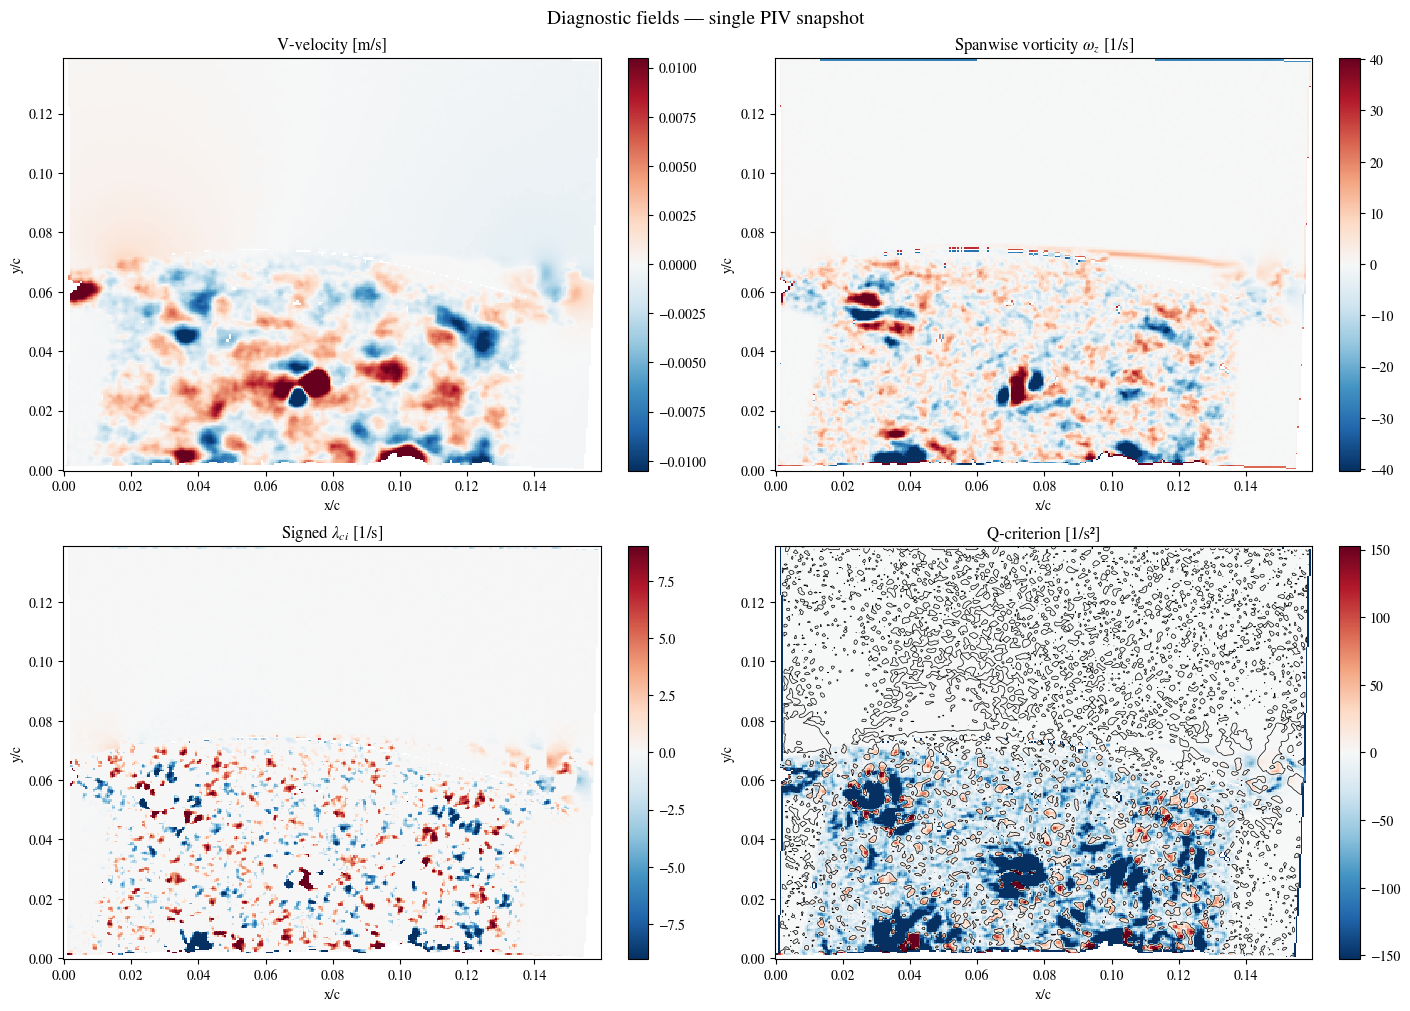

Detected 207 vortex cores using λ_ci
Detected 49 vortex cores using Q > 0
Vortex cores in shear layer: 0
Need ≥ 2 cores for spacing analysis. Try adjusting thresholds.


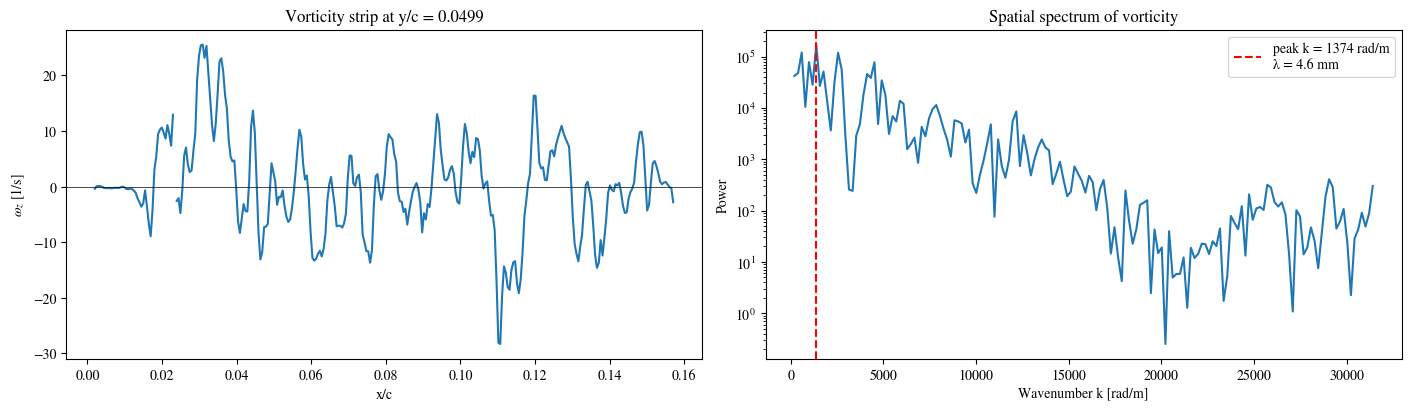

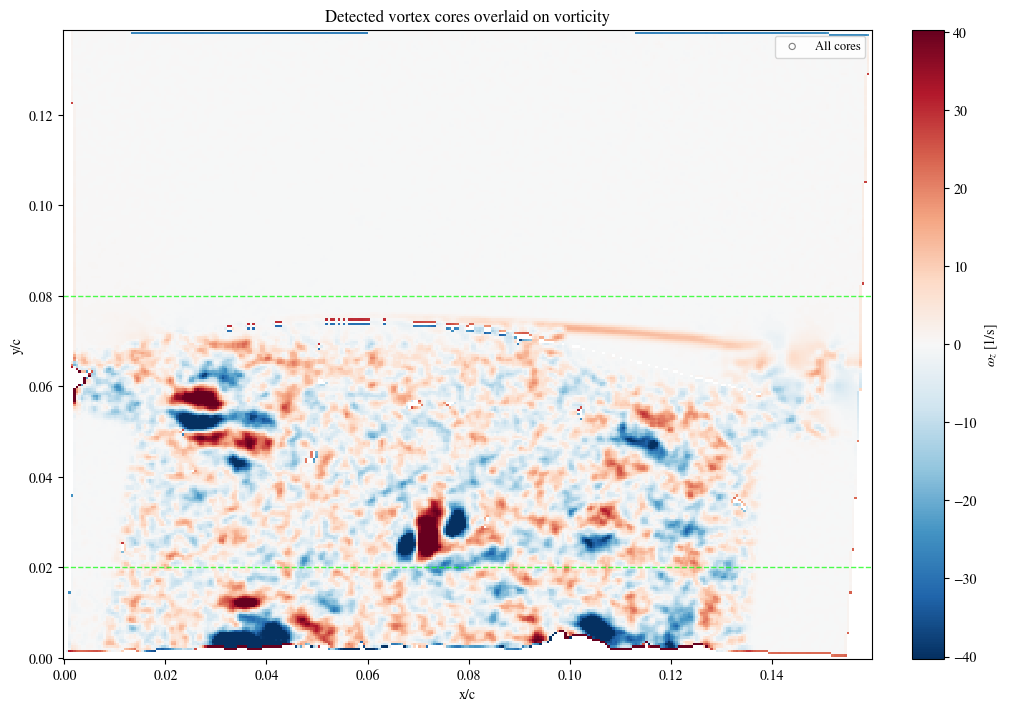

In [ ]:
# =============================================================================
# Vortex Core Spacing & Frequency Identification from Instantaneous PIV
# =============================================================================
# This script:
#   1. Loads instantaneous PIV data (LaVision format)
#   2. Computes vorticity, swirling strength (λ_ci), and Q-criterion (corrected)
#   3. Identifies discrete vortex cores in the shear layer
#   4. Extracts streamwise spacing between cores
#   5. Converts spacing to wavenumber and estimates temporal frequency
#      via a convection velocity estimate
# =============================================================================

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
from scipy.signal import find_peaks

# ── If using LaVision Python module ──
# import lavision as lv

# %% ═══════════════════════════════════════════════════════════════════════════
#  0.  USER PARAMETERS
# ═══════════════════════════════════════════════════════════════════════════════

# --- Paths (adjust to your setup) ---
piv_root = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/PIV/N65_WT_PIV_Flow_Fields"
mi_root  = r"/content/drive/MyDrive/Wind Tunnel Shared/Experimental Campaigns/24-01_Naca_651412_Campaign/Model Installation/InstallationRunFolders"

project_run = 1117
project = f"CJK_NACA651412_RUN{project_run}"
project_path = os.path.join(piv_root, project)
photo_dir = os.path.join(mi_root, f"Run{project_run}")

# --- Physical parameters ---
c = 0.2          # chord length [m]
run = 1178       # PIV run number

# --- Convection velocity estimate ---
# Typically U_c ≈ 0.5*(U_freestream + U_recirculation)
# or U_c ≈ 0.5 * U_inf for a separated shear layer.
# Adjust after inspecting your mean velocity profile.
U_inf = None      # Will be estimated from data if None

# --- Vortex detection thresholds (tune these) ---
LAMCI_THRESHOLD_FACTOR = 2.0   # multiples of std above mean
Q_THRESHOLD_FACTOR     = 2.0   # multiples of std above mean
MIN_VORTEX_AREA_PX     = 4     # minimum connected-component size [pixels]

# %% ═══════════════════════════════════════════════════════════════════════════
#  1.  LOAD PIV DATA
# ═══════════════════════════════════════════════════════════════════════════════

run_dir = next(f for f in os.listdir(project_path)
               if f.startswith(f"RUN{run}") and not f.endswith(".set"))
run_path = os.path.join(project_path, run_dir)

inst_piv_path = os.path.join(run_path, "PIV_MP(3x16x16_50%ov_ImgCorr)")

buffer = lv.read_set(inst_piv_path)
frames = buffer[0]

piv   = frames[0].as_masked_array()
scale = frames[0].scales.x.slope          # [mm/pixel or mm/box]
unit  = frames[0].scales.x.unit
print(f"Scale: {scale} {unit}/box")

# --- Extract velocity components ---
mask = piv.mask["u"][::-1, ::-1]
U_raw = piv.data["u"][::-1, ::-1].astype(float)
V_raw = piv.data["v"][::-1, ::-1].astype(float)

# Convert mm/s → m/s  (LaVision default is mm/s)
U = U_raw / 1000.0
V = V_raw / 1000.0
U[mask] = np.nan
V[mask] = np.nan

# --- Build physical grid in metres ---
dx_m = scale / 1000.0                       # box spacing in metres
x_phys = np.arange(U.shape[1]) * dx_m       # [m]
y_phys = np.arange(U.shape[0]) * dx_m       # [m]
X_m, Y_m = np.meshgrid(x_phys, y_phys)

# Also keep a normalised grid for plotting
X_c = X_m / c
Y_c = Y_m / c
dx = np.median(np.diff(x_phys))
dy = np.median(np.diff(y_phys))

print(f"Grid spacing: dx = {dx*1e3:.3f} mm, dy = {dy*1e3:.3f} mm")
print(f"Field size : {X_m.max()*1e3:.1f} x {Y_m.max()*1e3:.1f} mm")

# %% ═══════════════════════════════════════════════════════════════════════════
#  2.  VELOCITY GRADIENTS  (all in SI: 1/s)
# ═══════════════════════════════════════════════════════════════════════════════

def safe_gradient(F, dx, dy, mask):
    """Compute gradient, treating masked points as 0 to avoid NaN propagation."""
    F_filled = F.copy()
    F_filled[mask] = 0.0
    dF_dy, dF_dx = np.gradient(F_filled, dy, dx)
    dF_dx[mask] = np.nan
    dF_dy[mask] = np.nan
    return dF_dy, dF_dx


dU_dy, dU_dx = safe_gradient(U, dx, dy, mask)
dV_dy, dV_dx = safe_gradient(V, dx, dy, mask)

# %% ═══════════════════════════════════════════════════════════════════════════
#  3.  VORTEX IDENTIFICATION CRITERIA
# ═══════════════════════════════════════════════════════════════════════════════

# ---- 3a. Spanwise vorticity  ω_z = ∂V/∂x − ∂U/∂y  [1/s] ----
omega_z = dV_dx - dU_dy

# ---- 3b. Swirling strength  λ_ci  ----
#  Eigenvalues of the 2-D velocity gradient tensor:
#    | dU/dx  dU/dy |
#    | dV/dx  dV/dy |
#  λ = 0.5*(tr ± sqrt(tr² − 4·det))
#  where tr = dU/dx + dV/dy,  det = dU/dx·dV/dy − dU/dy·dV/dx
#  Complex eigenvalues (swirling) when discriminant < 0.
tr  = dU_dx + dV_dy
det = dU_dx * dV_dy - dU_dy * dV_dx
disc = tr**2 - 4.0 * det

lamci = np.zeros_like(U)
swirl_mask = disc < 0.0
lamci[swirl_mask] = 0.5 * np.sqrt(-disc[swirl_mask])
lamci[mask] = np.nan

# Signed swirling strength (retains rotation sense)
lamci_signed = np.sign(omega_z) * lamci

# ---- 3c. Q-criterion (correct 2-D form) ----
#  Q = ½ (‖Ω‖_F² − ‖S‖_F²)
#
#  Strain-rate tensor S_ij:
#    S = [[dU/dx,            ½(dU/dy+dV/dx)],
#         [½(dU/dy+dV/dx),   dV/dy          ]]
#    ‖S‖_F² = S_ij S_ij = dU/dx² + dV/dy² + ½(dU/dy+dV/dx)²
#
#  Rotation tensor Ω_ij:
#    Ω = [[0,               ½(dU/dy−dV/dx)],
#         [½(dV/dx−dU/dy),  0              ]]
#    ‖Ω‖_F² = ½ ω_z²
#
#  Simplification for 2-D:
#    Q = −½ (dU/dx² + dV/dy²) − dU/dy · dV/dx

S2 = dU_dx**2 + dV_dy**2 + 0.5 * (dU_dy + dV_dx)**2   # ‖S‖²_F
Omega2 = 0.5 * omega_z**2                                # ‖Ω‖²_F
Q = 0.5 * (Omega2 - S2)
Q[mask] = np.nan

# %% ═══════════════════════════════════════════════════════════════════════════
#  4.  DIAGNOSTIC PLOTS  (improved colour limits)
# ═══════════════════════════════════════════════════════════════════════════════

# Helper: robust colour limits (clip at percentiles)
def clim_pct(field, pct=99):
    v = np.abs(field[np.isfinite(field)])
    return np.percentile(v, pct)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), constrained_layout=True)

# (a) V-velocity
vlim = clim_pct(V, 99)
im0 = axes[0, 0].pcolormesh(X_c, Y_c, V, cmap='RdBu_r', vmin=-vlim, vmax=vlim, shading='nearest')
axes[0, 0].set_title('V-velocity [m/s]'); axes[0, 0].set_xlabel('x/c'); axes[0, 0].set_ylabel('y/c')
fig.colorbar(im0, ax=axes[0, 0])

# (b) Vorticity — use symmetric limits centred on 0
wlim = clim_pct(omega_z, 99)
im1 = axes[0, 1].pcolormesh(X_c, Y_c, omega_z, cmap='RdBu_r', vmin=-wlim, vmax=wlim, shading='nearest')
axes[0, 1].set_title(r'Spanwise vorticity $\omega_z$ [1/s]'); axes[0, 1].set_xlabel('x/c'); axes[0, 1].set_ylabel('y/c')
fig.colorbar(im1, ax=axes[0, 1])

# (c) Swirling strength (signed)
llim = clim_pct(lamci_signed, 99)
im2 = axes[1, 0].pcolormesh(X_c, Y_c, lamci_signed, cmap='RdBu_r', vmin=-llim, vmax=llim, shading='nearest')
axes[1, 0].set_title(r'Signed $\lambda_{ci}$ [1/s]'); axes[1, 0].set_xlabel('x/c'); axes[1, 0].set_ylabel('y/c')
fig.colorbar(im2, ax=axes[1, 0])

# (d) Q-criterion — clip to make structure visible
Qlim = clim_pct(Q, 95)
im3 = axes[1, 1].pcolormesh(X_c, Y_c, Q, cmap='RdBu_r', vmin=-Qlim, vmax=Qlim, shading='nearest')
axes[1, 1].contour(X_c, Y_c, Q, levels=[0.0], colors='k', linewidths=0.5)
axes[1, 1].set_title('Q-criterion [1/s²]'); axes[1, 1].set_xlabel('x/c'); axes[1, 1].set_ylabel('y/c')
fig.colorbar(im3, ax=axes[1, 1])

plt.suptitle('Diagnostic fields — single PIV snapshot', fontsize=14)
plt.savefig('diagnostic_fields.png', dpi=200)
plt.show()

# %% ═══════════════════════════════════════════════════════════════════════════
#  5.  VORTEX CORE DETECTION
# ═══════════════════════════════════════════════════════════════════════════════
#
#  Strategy: threshold λ_ci (or Q > 0), label connected components,
#  find centroids.  λ_ci is generally cleaner for shear-layer vortices.

def detect_vortex_cores(field, mask, threshold_factor=2.0, min_area=4,
                        use_positive=True):
    """
    Detect vortex cores from a scalar indicator field.

    Parameters
    ----------
    field : 2-D array  (e.g. λ_ci or Q)
    mask : bool array   (True where data is invalid)
    threshold_factor : float
        threshold = mean + threshold_factor * std  (computed over valid points)
    min_area : int
        Minimum connected-component area in grid points.
    use_positive : bool
        If True, detect where field > threshold.
        If False, detect where field < -threshold (for negative Q / vorticity).

    Returns
    -------
    centroids : (N, 2) array  — (row, col) of each vortex centre-of-mass
    labels : labelled array
    n_vortices : int
    """
    valid = np.isfinite(field) & ~mask
    vals  = field[valid]

    if use_positive:
        thr = np.nanmean(vals) + threshold_factor * np.nanstd(vals)
        binary = (field > thr) & valid
    else:
        thr = np.nanmean(vals) - threshold_factor * np.nanstd(vals)
        binary = (field < thr) & valid

    # Label connected components
    structure = ndimage.generate_binary_structure(2, 2)  # 8-connectivity
    labels, n = ndimage.label(binary, structure=structure)

    # Filter small blobs
    centroids = []
    for i in range(1, n + 1):
        component = labels == i
        if component.sum() < min_area:
            labels[component] = 0
            continue
        # Weighted centroid (weight by |field|)
        weights = np.abs(field) * component
        cy, cx = ndimage.center_of_mass(weights)
        centroids.append((cy, cx))

    # Relabel after filtering
    labels, n_final = ndimage.label(labels > 0, structure=structure)
    centroids = np.array(centroids)
    return centroids, labels, n_final


# Detect using λ_ci (always positive, so use_positive=True)
cores_lci, labels_lci, n_lci = detect_vortex_cores(
    lamci, mask,
    threshold_factor=LAMCI_THRESHOLD_FACTOR,
    min_area=MIN_VORTEX_AREA_PX,
    use_positive=True
)
print(f"Detected {n_lci} vortex cores using λ_ci")

# Also try with Q > 0 (rotation-dominated regions)
cores_Q, labels_Q, n_Q = detect_vortex_cores(
    Q, mask,
    threshold_factor=0.0,        # Q > 0 is already meaningful
    min_area=MIN_VORTEX_AREA_PX,
    use_positive=True
)
print(f"Detected {n_Q} vortex cores using Q > 0")

# %% ═══════════════════════════════════════════════════════════════════════════
#  6.  MAP CENTROIDS TO PHYSICAL / NORMALISED COORDINATES
# ═══════════════════════════════════════════════════════════════════════════════

def cores_to_physical(centroids, x_phys, y_phys, c):
    """Convert (row, col) centroids to (x/c, y/c) coordinates."""
    if len(centroids) == 0:
        return np.empty((0, 2))
    rows = centroids[:, 0]
    cols = centroids[:, 1]
    x_vals = np.interp(cols, np.arange(len(x_phys)), x_phys) / c
    y_vals = np.interp(rows, np.arange(len(y_phys)), y_phys) / c
    return np.column_stack([x_vals, y_vals])

cores_xy = cores_to_physical(cores_lci, x_phys, y_phys, c)

# %% ═══════════════════════════════════════════════════════════════════════════
#  7.  RESTRICT TO THE SHEAR LAYER & SORT BY STREAMWISE POSITION
# ═══════════════════════════════════════════════════════════════════════════════
#
#  The shear layer is roughly between y/c ≈ 0.04 and 0.08 from your plots.
#  Adjust these bounds as needed.

SHEAR_LAYER_Y_MIN = 0.02    # y/c lower bound
SHEAR_LAYER_Y_MAX = 0.08    # y/c upper bound

if len(cores_xy) > 0:
    in_shear = ((cores_xy[:, 1] >= SHEAR_LAYER_Y_MIN) &
                (cores_xy[:, 1] <= SHEAR_LAYER_Y_MAX))
    shear_cores = cores_xy[in_shear]
    # Sort by x/c
    order = np.argsort(shear_cores[:, 0])
    shear_cores = shear_cores[order]
    print(f"Vortex cores in shear layer: {len(shear_cores)}")
else:
    shear_cores = np.empty((0, 2))
    print("No cores detected — try lowering threshold.")

# %% ═══════════════════════════════════════════════════════════════════════════
#  8.  VORTEX SPACING, WAVENUMBER, AND FREQUENCY
# ═══════════════════════════════════════════════════════════════════════════════

if len(shear_cores) >= 2:
    # Streamwise spacing Δ(x/c) between consecutive cores
    delta_xc = np.diff(shear_cores[:, 0])          # in x/c units
    delta_x  = delta_xc * c                         # in metres

    print("\n── Vortex core spacings ──")
    for i, (dxc, dxm) in enumerate(zip(delta_xc, delta_x)):
        print(f"  Core {i} → {i+1}:  Δ(x/c) = {dxc:.4f},  Δx = {dxm*1e3:.2f} mm")

    mean_spacing_xc = np.mean(delta_xc)
    mean_spacing_m  = np.mean(delta_x)
    print(f"\n  Mean spacing: Δ(x/c) = {mean_spacing_xc:.4f},  "
          f"Δx = {mean_spacing_m*1e3:.2f} mm")

    # Spatial wavenumber
    wavelength = mean_spacing_m                       # [m]
    k = 2.0 * np.pi / wavelength                     # [rad/m]
    print(f"  Wavenumber k = {k:.1f} rad/m  (λ = {wavelength*1e3:.2f} mm)")

    # ── Estimate convection velocity ──
    # Option A: average U in the shear layer band
    sl_rows = ((Y_c[:, 0] >= SHEAR_LAYER_Y_MIN) &
               (Y_c[:, 0] <= SHEAR_LAYER_Y_MAX))
    U_sl = U[sl_rows, :]
    U_c_estimate = np.nanmean(U_sl)
    if U_inf is None:
        # Estimate freestream from upper part of field (y/c > 0.10)
        upper = Y_c[:, 0] > 0.10
        U_inf_est = np.nanmean(U[upper, :])
    else:
        U_inf_est = U_inf

    print(f"\n── Convection velocity estimates ──")
    print(f"  Mean U in shear layer : U_c = {U_c_estimate:.3f} m/s")
    print(f"  Freestream estimate   : U_∞ = {U_inf_est:.3f} m/s")
    print(f"  0.5 * U_∞             : {0.5*U_inf_est:.3f} m/s")

    # Use the shear-layer mean as the primary estimate
    U_c = U_c_estimate

    # Temporal frequency  f = U_c / λ  or  f = U_c * k / (2π)
    f_hz = U_c / wavelength
    St   = f_hz * c / U_inf_est    # Strouhal number based on chord

    print(f"\n── Frequency estimates (using U_c = {U_c:.3f} m/s) ──")
    print(f"  f = U_c / λ     = {f_hz:.1f} Hz")
    print(f"  ω = 2π f        = {2*np.pi*f_hz:.1f} rad/s")
    print(f"  St = f·c / U_∞  = {St:.3f}")

    # Also compute for each individual spacing
    f_individual = U_c / delta_x
    print(f"\n  Individual spacing frequencies: "
          f"{', '.join(f'{fi:.0f}' for fi in f_individual)} Hz")

else:
    print("Need ≥ 2 cores for spacing analysis. Try adjusting thresholds.")

# %% ═══════════════════════════════════════════════════════════════════════════
#  9.  ALTERNATIVE: SPECTRAL APPROACH  (1-D FFT of ω_z along shear layer)
# ═══════════════════════════════════════════════════════════════════════════════
#
#  Extract a streamwise strip of ω_z at the shear layer height and compute
#  its spatial spectrum.  This gives a wavenumber spectrum directly.

# Pick the row closest to the shear layer centre
y_sl_centre = 0.5 * (SHEAR_LAYER_Y_MIN + SHEAR_LAYER_Y_MAX)
j_sl = np.argmin(np.abs(Y_c[:, 0] - y_sl_centre))

omega_strip = omega_z[j_sl, :]
valid_strip = np.isfinite(omega_strip)
omega_clean = omega_strip.copy()
omega_clean[~valid_strip] = 0.0   # zero-fill gaps (or interpolate)

N = len(omega_clean)
# Spatial frequency axis
freq_spatial = np.fft.rfftfreq(N, d=dx)   # cycles/m
k_axis = 2 * np.pi * freq_spatial          # rad/m
power = np.abs(np.fft.rfft(omega_clean * np.hanning(N)))**2

fig, axes = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)

# Left: the strip
axes[0].plot(X_c[j_sl, :], omega_strip)
axes[0].set_xlabel('x/c'); axes[0].set_ylabel(r'$\omega_z$ [1/s]')
axes[0].set_title(f'Vorticity strip at y/c = {Y_c[j_sl,0]:.4f}')
axes[0].axhline(0, color='k', lw=0.5)

# Right: spatial power spectrum
axes[1].semilogy(k_axis[1:], power[1:])
axes[1].set_xlabel('Wavenumber k [rad/m]')
axes[1].set_ylabel('Power')
axes[1].set_title('Spatial spectrum of vorticity')

# Mark peak
peak_idx = np.argmax(power[1:]) + 1
k_peak = k_axis[peak_idx]
lambda_peak = 2 * np.pi / k_peak
axes[1].axvline(k_peak, color='r', ls='--', label=f'peak k = {k_peak:.0f} rad/m\n'
                f'λ = {lambda_peak*1e3:.1f} mm')
axes[1].legend()

plt.savefig('vorticity_spectrum.png', dpi=200)
plt.show()

# Spectral frequency estimate
if len(shear_cores) >= 2:
    f_spectral = U_c * k_peak / (2 * np.pi)
    print(f"\n── Spectral estimate ──")
    print(f"  Peak wavenumber : k = {k_peak:.0f} rad/m  →  λ = {lambda_peak*1e3:.1f} mm")
    print(f"  Frequency (U_c={U_c:.3f} m/s): f = {f_spectral:.0f} Hz")

# %% ═══════════════════════════════════════════════════════════════════════════
# 10.  SUMMARY PLOT — cores overlaid on vorticity
# ═══════════════════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(10, 7), constrained_layout=True)

wlim = clim_pct(omega_z, 99)
im = ax.pcolormesh(X_c, Y_c, omega_z, cmap='RdBu_r',
                   vmin=-wlim, vmax=wlim, shading='nearest')
fig.colorbar(im, ax=ax, label=r'$\omega_z$ [1/s]')

# Shear layer bounds
ax.axhline(SHEAR_LAYER_Y_MIN, color='lime', ls='--', lw=1, alpha=0.7)
ax.axhline(SHEAR_LAYER_Y_MAX, color='lime', ls='--', lw=1, alpha=0.7)

# All detected cores
if len(cores_xy) > 0:
    ax.scatter(cores_xy[:, 0], cores_xy[:, 1],
               s=20, facecolors='none', edgecolors='grey', linewidths=0.8,
               label='All cores')

# Shear layer cores
if len(shear_cores) > 0:
    ax.scatter(shear_cores[:, 0], shear_cores[:, 1],
               s=60, facecolors='none', edgecolors='yellow', linewidths=1.5,
               label='Shear-layer cores')
    # Draw spacing arrows
    for i in range(len(shear_cores) - 1):
        ax.annotate('', xy=shear_cores[i+1], xytext=shear_cores[i],
                    arrowprops=dict(arrowstyle='->', color='yellow', lw=1.2))

ax.set_xlabel('x/c'); ax.set_ylabel('y/c')
ax.set_title('Detected vortex cores overlaid on vorticity')
ax.legend(loc='upper right', fontsize=9)
plt.savefig('vortex_cores_overlay.png', dpi=200)
plt.show()

# %% ═══════════════════════════════════════════════════════════════════════════
# 11.  LOOP OVER MULTIPLE FRAMES (skeleton)
# ═══════════════════════════════════════════════════════════════════════════════
#
#  For statistical robustness, repeat the analysis over many instantaneous
#  snapshots and build a histogram/PDF of vortex spacings.

all_spacings = []

for frame_idx in range(len(frames)):
    piv_i = frames[frame_idx].as_masked_array()
    mask_i = piv_i.mask["u"][::-1, ::-1]
    U_i = piv_i.data["u"][::-1, ::-1].astype(float) / 1000.0
    V_i = piv_i.data["v"][::-1, ::-1].astype(float) / 1000.0
    U_i[mask_i] = np.nan
    V_i[mask_i] = np.nan

    dU_dy_i, dU_dx_i = safe_gradient(U_i, dx, dy, mask_i)
    dV_dy_i, dV_dx_i = safe_gradient(V_i, dx, dy, mask_i)

    tr_i  = dU_dx_i + dV_dy_i
    det_i = dU_dx_i * dV_dy_i - dU_dy_i * dV_dx_i
    disc_i = tr_i**2 - 4.0 * det_i
    lamci_i = np.zeros_like(U_i)
    sw = disc_i < 0
    lamci_i[sw] = 0.5 * np.sqrt(-disc_i[sw])
    lamci_i[mask_i] = np.nan

    cores_i, _, _ = detect_vortex_cores(
        lamci_i, mask_i,
        threshold_factor=LAMCI_THRESHOLD_FACTOR,
        min_area=MIN_VORTEX_AREA_PX
    )
    if len(cores_i) < 2:
        continue

    xy_i = cores_to_physical(cores_i, x_phys, y_phys, c)
    in_sl = ((xy_i[:, 1] >= SHEAR_LAYER_Y_MIN) &
             (xy_i[:, 1] <= SHEAR_LAYER_Y_MAX))
    sl_i = xy_i[in_sl]
    if len(sl_i) < 2:
        continue
    sl_i = sl_i[np.argsort(sl_i[:, 0])]
    spacings_i = np.diff(sl_i[:, 0]) * c  # in metres
    all_spacings.extend(spacings_i.tolist())

    if frame_idx % 50 == 0:
        print(f"  Frame {frame_idx}/{len(frames)}: {len(sl_i)} SL cores")

all_spacings = np.array(all_spacings)

if len(all_spacings) > 5:
    fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
    ax.hist(all_spacings * 1e3, bins=40, edgecolor='k', alpha=0.7)
    ax.axvline(np.median(all_spacings) * 1e3, color='r', ls='--',
               label=f'Median = {np.median(all_spacings)*1e3:.1f} mm')
    ax.set_xlabel('Vortex spacing [mm]')
    ax.set_ylabel('Count')
    ax.set_title(f'Vortex spacing distribution ({len(frames)} frames)')
    ax.legend()
    plt.savefig('spacing_histogram.png', dpi=200)
    plt.show()

    # Summary statistics
    lam_med = np.median(all_spacings)
    f_med = U_c / lam_med if 'U_c' in dir() else np.nan
    print(f"\n═══ SUMMARY (over {len(frames)} frames) ═══")
    print(f"  Median vortex spacing : {lam_med*1e3:.1f} mm  ({lam_med/c:.4f} x/c)")
    print(f"  Mean vortex spacing   : {np.mean(all_spacings)*1e3:.1f} mm")
    print(f"  Std                   : {np.std(all_spacings)*1e3:.1f} mm")
    if not np.isnan(f_med):
        print(f"  Estimated frequency   : {f_med:.0f} Hz  (St = {f_med*c/U_inf_est:.3f})")